In [66]:
import yfinance as yf
import datetime

start = datetime.datetime(2020, 1, 1)
end = datetime.datetime(2020, 12, 31)

ceva = yf.download("CEVA", start=start, end=end)
google = yf.download("GOOGL", start=start, end=end)
tesla = yf.download("TSLA", start=start, end=end)
adbe = yf.download("ADBE", start=start, end=end)
print(adbe.head())

C:\Users\admin\AppData\Local\Temp\ipykernel_10108\1027835569.py:7: FutureWarning: YF.download() has changed argument auto_adjust default to True
  ceva = yf.download("CEVA", start=start, end=end)
[*********************100%***********************]  1 of 1 completed
C:\Users\admin\AppData\Local\Temp\ipykernel_10108\1027835569.py:8: FutureWarning: YF.download() has changed argument auto_adjust default to True
  google = yf.download("GOOGL", start=start, end=end)
[*********************100%***********************]  1 of 1 completed
C:\Users\admin\AppData\Local\Temp\ipykernel_10108\1027835569.py:9: FutureWarning: YF.download() has changed argument auto_adjust default to True
  tesla = yf.download("TSLA", start=start, end=end)
[*********************100%***********************]  1 of 1 completed
C:\Users\admin\AppData\Local\Temp\ipykernel_10108\1027835569.py:10: FutureWarning: YF.download() has changed argument auto_adjust default to True
  adbe = yf.download("ADBE", start=start, end=end)
[***

Price            Close        High         Low        Open   Volume
Ticker            ADBE        ADBE        ADBE        ADBE     ADBE
Date                                                               
2020-01-02  334.429993  334.480011  329.170013  330.000000  1990100
2020-01-03  331.809998  332.980011  328.690002  329.170013  1577600
2020-01-06  333.709991  333.910004  328.190002  328.290009  1874700
2020-01-07  333.390015  334.790009  332.309998  334.149994  2500800
2020-01-08  337.869995  339.230011  333.399994  333.809998  2248500


In [23]:
print(tesla.head())

Price           Close       High        Low       Open     Volume
Ticker           TSLA       TSLA       TSLA       TSLA       TSLA
Date                                                             
2020-01-02  28.684000  28.713333  28.114000  28.299999  142981500
2020-01-03  29.534000  30.266666  29.128000  29.366667  266677500
2020-01-06  30.102667  30.104000  29.333332  29.364668  151995000
2020-01-07  31.270666  31.441999  30.224001  30.760000  268231500
2020-01-08  32.809334  33.232666  31.215334  31.580000  467164500


In [24]:
print(google.head())

Price           Close       High        Low       Open    Volume
Ticker          GOOGL      GOOGL      GOOGL      GOOGL     GOOGL
Date                                                            
2020-01-02  68.026031  68.026031  66.923149  67.018577  27278000
2020-01-03  67.670143  68.278001  66.964377  66.998178  23408000
2020-01-06  69.473846  69.499192  67.147300  67.178606  46768000
2020-01-07  69.339638  69.756639  69.163198  69.605545  34330000
2020-01-08  69.833183  70.171653  69.216384  69.325228  35314000


In [25]:
print(ceva.head())

Price           Close       High        Low       Open  Volume
Ticker           CEVA       CEVA       CEVA       CEVA    CEVA
Date                                                          
2020-01-02  27.830000  28.000000  27.090000  27.350000   95400
2020-01-03  27.260000  27.500000  26.959999  27.490000  114600
2020-01-06  27.180000  27.480000  26.650000  26.990000  106100
2020-01-07  27.320000  27.690001  26.590000  27.280001   67800
2020-01-08  27.379999  27.709999  27.190001  27.400000   58500


In [80]:
stocks = pd.concat(
    [ceva["Close"], google["Close"], tesla["Close"], adbe["Close"]],
    axis=1
)

# Rename columns for clarity
stocks.columns = ["CEVA", "GOOGL", "TSLA", "ADBE"]

In [81]:
stocks

,CEVA,GOOGL,TSLA,ADBE
Date,,,,
2020-01-02,27.830000,68.026031,28.684000,334.429993
2020-01-03,27.260000,67.670143,29.534000,331.809998
2020-01-06,27.180000,69.473846,30.102667,333.709991
2020-01-07,27.320000,69.339638,31.270666,333.390015
2020-01-08,27.379999,69.833183,32.809334,337.869995
...,...,...,...,...
2020-12-23,40.709999,85.896347,215.326660,496.910004
2020-12-24,42.209999,86.191086,220.589996,499.859985
2020-12-28,42.919998,88.169220,221.229996,498.950012


In [30]:
# formula used for returns 

$r_t = \frac{P_t}{P_{t-1}}$


In [129]:
print(stocks.shift(1).head())

             CEVA      GOOGL       TSLA        ADBE
Date                                               
2020-01-02    NaN        NaN        NaN         NaN
2020-01-03  27.83  68.026031  28.684000  334.429993
2020-01-06  27.26  67.670143  29.534000  331.809998
2020-01-07  27.18  69.473846  30.102667  333.709991
2020-01-08  27.32  69.339638  31.270666  333.390015


In [31]:
returns = stocks/stocks.shift(1)

In [83]:
returns

,CEVA,GOOGL,TSLA,ADBE
Date,,,,
2020-01-02,NaN,NaN,NaN,NaN
2020-01-03,0.979519,0.994768,1.029633,0.992166
2020-01-06,0.997065,1.026654,1.019255,1.005726
2020-01-07,1.005151,0.998068,1.038801,0.999041
2020-01-08,1.002196,1.007118,1.049205,1.013438
...,...,...,...,...
2020-12-23,1.002956,1.004656,1.008808,0.985600
2020-12-24,1.036846,1.003431,1.024443,1.005937
2020-12-28,1.016821,1.022951,1.002901,0.998180


$\mathbf{logr}_t = \ln\left(\frac{P_t}{P_{t-1}}\right)$


In [33]:
import numpy as np
logReturns = np.log(returns)
logReturns

,CEVA,GOOGL,TSLA,ADBE
Date,,,,
2020-01-02,NaN,NaN,NaN,NaN
2020-01-03,-0.020694,-0.005245,0.029203,-0.007865
2020-01-06,-0.002939,0.026305,0.019072,0.005710
2020-01-07,0.005138,-0.001934,0.038067,-0.000959
2020-01-08,0.002194,0.007093,0.048033,0.013348
...,...,...,...,...
2020-12-23,0.002952,0.004646,0.008769,-0.014505
2020-12-24,0.036183,0.003425,0.024150,0.005919
2020-12-28,0.016681,0.022691,0.002897,-0.001822


$$
SHARPE \quad RATIO
$$



$$
S = \frac{R_p - R_f}{\sigma_p}
$$



In [35]:
# for every strategy that you suggest theres a corresponding sharpe ratio
#   w = [ w1 , w2 , w3 , w4 ] 
#  distributing the weights(fund) into four parts


### 🔹 Sharpe Ratio for a Portfolio with 4 Assets

The Sharpe Ratio is:

$$
S = \frac{R_p - R_f}{\sigma_p}
$$

The Sharpe Ratio is a way to measure how well an investment (like a stock or portfolio) compensates you for the risk you’re taking.

---

#### ✅ Portfolio Return

$$
R_p = \sum_{k=1}^4 w_k R_k = w_1R_1 + w_2R_2 + w_3R_3 + w_4R_4
$$

---

#### ✅ Portfolio Variance

$$
\sigma_p^2 = \sum_{i=1}^4 \sum_{j=1}^4 w_i w_j \, \text{Cov}(R_i, R_j)
$$

or in matrix form:

$$
\sigma_p^2 = w^T \Sigma w
$$

where

$$
w =
\begin{bmatrix}
w_1 \\ w_2 \\ w_3 \\ w_4
\end{bmatrix},
\quad
\Sigma =
\begin{bmatrix}
\sigma_{11} & \sigma_{12} & \sigma_{13} & \sigma_{14} \\
\sigma_{21} & \sigma_{22} & \sigma_{23} & \sigma_{24} \\
\sigma_{31} & \sigma_{32} & \sigma_{33} & \sigma_{34} \\
\sigma_{41} & \sigma_{42} & \sigma_{43} & \sigma_{44} \\
\end{bmatrix}
$$

---

#### ✅ Final Sharpe Ratio

$$
S = \frac{\sum_{k=1}^4 w_k R_k - R_f}{\sqrt{w^T \Sigma w}}
$$


In [91]:
noOfPortfolios = 10000

weights = np.zeros((noOfPortfolios, 4))
expectedReturn = np.zeros(noOfPortfolios)
expectedVolatility = np.zeros(noOfPortfolios)
sharpeRatio = np.zeros(noOfPortfolios)

meanLogRet = logReturns.mean()
sigma = logReturns.cov()

for k in range(noOfPortfolios):
    # generate random weight vector
    w = np.random.random(4)
    w = w / np.sum(w)
    weights[k, :] = w  

    # expected log return
    expectedReturn[k] = np.sum(meanLogRet * w)

    # expected volatility
    expectedVolatility[k] = np.sqrt(np.dot(w.T, np.dot(sigma, w)))

    # sharpe ratio
    sharpeRatio[k] = expectedReturn[k] / expectedVolatility[k]  


In [92]:
sharpeRatio

array([0.11887756, 0.07054572, 0.12201881, ..., 0.11123245, 0.08832657,
       0.09014558])

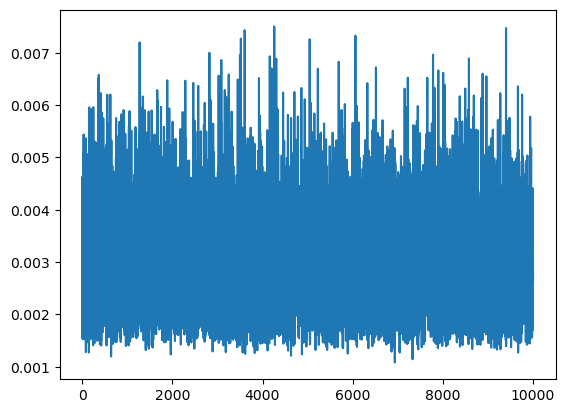

In [93]:
import matplotlib.pyplot as plt
plt.plot(expectedReturn)

In [94]:
weights[0]

array([0.19753572, 0.28781376, 0.35272653, 0.16192399])

In [95]:
# finding the index where the sharpe ratio is most

maxIndex = sharpeRatio.argmax()
weights[maxIndex]


array([0.05327022, 0.06029679, 0.88225644, 0.00417655])

$$ 
RETURNS \quad VS \quad VOLATALITY
$$

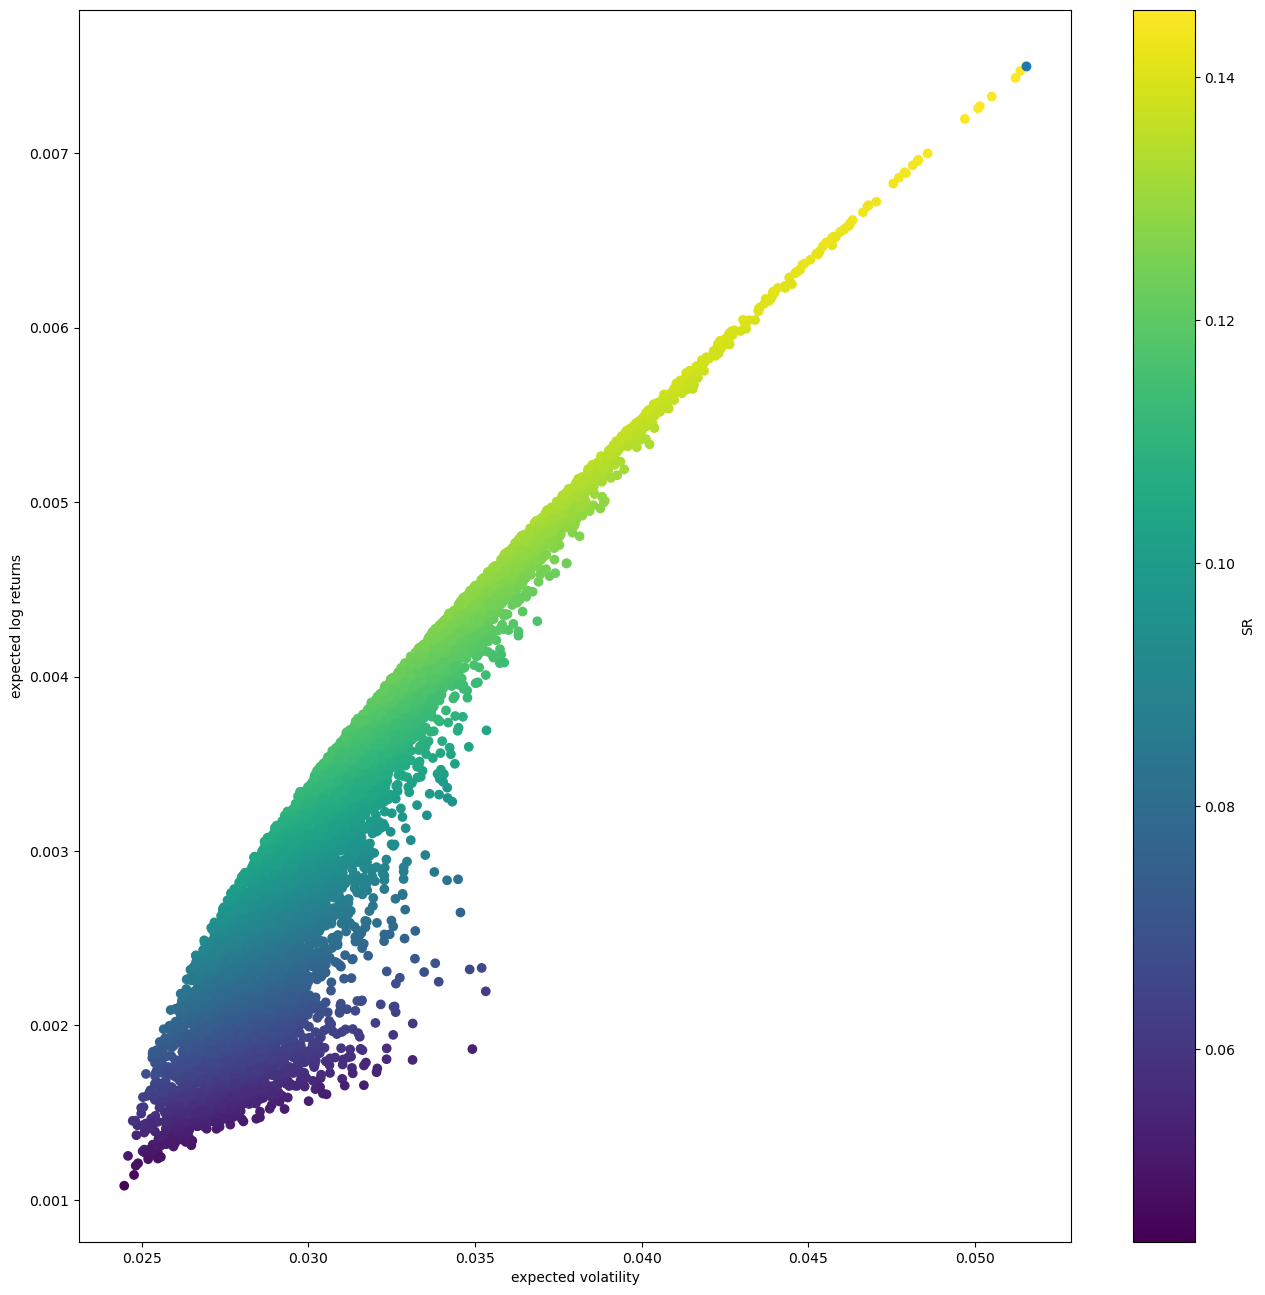

In [96]:
import matplotlib.pyplot as plt
plt.figure(figsize = (16,16))
plt.scatter(expectedVolatility , expectedReturn , c= sharpeRatio)
plt.xlabel('expected volatility')
plt.ylabel('expected log returns')
plt.colorbar(label = 'SR')
plt.scatter(expectedVolatility[maxIndex] , expectedReturn[maxIndex])
plt.show();


# Efficient Markowitz Frontier



In [97]:
# basically we are looking for the best portfolio that minimizes the risk 
# and achieves minimum expected return

In [98]:
# maximising return minimising risk

In [99]:
#  equal to saying maximise the sharpe return  

In [100]:
# 1. find the portfolio for risk at 0.001


In [107]:
target_risk = 0.001

# Find index of portfolio whose risk is closest to target
index = np.argmin(np.abs(expectedVolatility - target_risk))

# Corresponding return and weights
portfolio_return_at_05 = expectedReturn[index]
portfolio_risk_at_05 = expectedVolatility[index]
portfolio_weights_at_05 = weights[index]

print("Risk:", portfolio_risk_at_05)
print("Return:", portfolio_return_at_05)
print("Weights:", portfolio_weights_at_05)

Risk: 0.024471482399305525
Return: 0.0010805491592065105
Weights: [0.07030387 0.85504606 0.00360687 0.0710432 ]




$$
OPTIMISED
$$


In [108]:
from scipy.optimize import minimize
# how minimise works 
# for a function f(x), find x which minimises f(x).
# Function to minimize → negative Sharpe ratio (-Sharpe)

# Variables → portfolio weights (w1, w2, w3, w4)

# Constraints → weights sum to 1, weights ≥ 0 

In [114]:

def negSR(w):
    w = np.array(w);
    R = np.sum(w*meanLogRet)
    V = np.sqrt(np.dot(w.T, np.dot(sigma, w)))
    SR = R/V
    return -1*SR

def checkSumToOne(w):
    return np.sum(w)-1
w0 = [0.25 , 0.25 , 0.25, 0.25]
bounds = ((0,1),(0,1),(0,1),(0,1))
constraints = ({'type':'eq', 'fun': checkSumToOne})
w_opt = minimize(negSR , w0 , method = 'SLSQP' , bounds = bounds , constraints = constraints)

In [115]:
w_opt

 message: Optimization terminated successfully
 success: True
  status: 0
     fun: -0.14701915753123881
       x: [ 1.561e-17  3.123e-17  1.000e+00  3.773e-17]
     nit: 6
     jac: [ 6.022e-03  1.257e-02 -0.000e+00  1.141e-02]
    nfev: 30
    njev: 6

In [116]:
w_opt.x

array([1.56125113e-17, 3.12250226e-17, 1.00000000e+00, 3.77302356e-17])